In [8]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [9]:
from glob import glob
from collections import defaultdict

files = glob('processed-data/**/registration/**_accepted_only_registered_ids.npy', recursive=True)

data = defaultdict(list)
for file in files:
    reg_matrix = np.load(file)
    
    print(reg_matrix.shape)
    N = reg_matrix.shape[0]
    K = [1,2,3,4,5,6,7,8,9]

    for k in K:
        # Use number of non-NaNs in each row to filter out components that were not registered in enough sessions
        reg_matrix_filtered = np.array(np.nan_to_num(reg_matrix[np.sum(~np.isnan(reg_matrix), axis=1) >= k]), dtype=int)
        n = reg_matrix_filtered.shape[0]
        data['Percentage'].extend([round(n/N * 100, 2)])
        data['K'].extend([k])

data


(316, 13)
(345, 13)
(325, 13)
(607, 15)
(1440, 10)
(1355, 10)
(1833, 10)
(1289, 10)
(267, 15)
(656, 16)


defaultdict(list,
            {'Percentage': [100.0,
              58.23,
              36.08,
              22.78,
              15.19,
              10.44,
              5.06,
              1.9,
              1.58,
              100.0,
              63.19,
              44.93,
              32.17,
              22.9,
              16.23,
              9.86,
              6.09,
              2.32,
              100.0,
              57.23,
              40.31,
              27.69,
              20.0,
              13.54,
              6.77,
              3.69,
              2.15,
              100.0,
              49.75,
              20.92,
              10.87,
              4.61,
              1.98,
              0.82,
              0.33,
              0.0,
              100.0,
              67.57,
              44.24,
              26.88,
              14.31,
              6.18,
              1.94,
              0.69,
              0.21,
              100.0,
              67.08,
   

In [10]:
from glob import glob
from collections import defaultdict

files2 = glob('processed-data/Oct_2024_synthetic/registration/**_registered_ids.npy', recursive=True)

data2 = defaultdict(list)
for file in files2:
    reg_matrix = np.load(file)
    
    print(reg_matrix.shape)
    N = reg_matrix.shape[0]
    K = [1,2,3,4,5,6,7,8,9]

    for k in K:
        # Use number of non-NaNs in each row to filter out components that were not registered in enough sessions
        reg_matrix_filtered = np.array(np.nan_to_num(reg_matrix[np.sum(~np.isnan(reg_matrix), axis=1) >= k]), dtype=int)
        n = reg_matrix_filtered.shape[0]
        data2['Percentage'].extend([round(n/N * 100, 2)])
        data2['K'].extend([k])

data2

(185, 6)
(538, 6)
(614, 6)
(182, 6)
(858, 6)
(114, 6)
(719, 6)
(616, 6)
(644, 6)
(709, 6)
(657, 6)
(780, 6)
(474, 6)
(174, 6)
(242, 6)
(678, 6)
(304, 6)
(302, 6)
(804, 6)
(371, 6)


defaultdict(list,
            {'Percentage': [100.0,
              95.14,
              92.43,
              87.03,
              67.03,
              34.05,
              0.0,
              0.0,
              0.0,
              100.0,
              88.66,
              78.25,
              60.97,
              36.43,
              14.5,
              0.0,
              0.0,
              0.0,
              100.0,
              83.22,
              64.98,
              40.55,
              19.87,
              5.54,
              0.0,
              0.0,
              0.0,
              100.0,
              89.56,
              50.55,
              36.81,
              7.14,
              4.4,
              0.0,
              0.0,
              0.0,
              100.0,
              86.36,
              73.19,
              51.28,
              28.55,
              8.04,
              0.0,
              0.0,
              0.0,
              100.0,
              96.49,
              95.

In [11]:
reg_matrix = np.load(file)
np.matrix.view(reg_matrix)

array([[  0.,  nan,   0.,   0.,  nan,  nan],
       [  1.,   0.,  nan,   1.,   0.,   0.],
       [  2.,   1.,   2.,   3.,   3.,   2.],
       ...,
       [ nan,  nan,  nan,  nan,  nan, 204.],
       [ nan,  nan,  nan,  nan,  nan, 238.],
       [ nan,  nan,  nan,  nan,  nan, 270.]])

In [12]:
import pandas as pd

data = pd.DataFrame(data)
data.head()

data2 = pd.DataFrame(data2)
data2.head()

,Percentage,K
0,100.00,1
1,95.14,2
2,92.43,3
3,87.03,4
4,67.03,5


/home/aagafono/miniconda3/envs/mescore/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 55.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/aagafono/miniconda3/envs/mescore/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 55.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/aagafono/miniconda3/envs/mescore/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 10.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/home/aagafono/miniconda3/envs/mescore/lib/python3.11/site-packages/seaborn/categorical.py:3399: UserWarning: 45.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


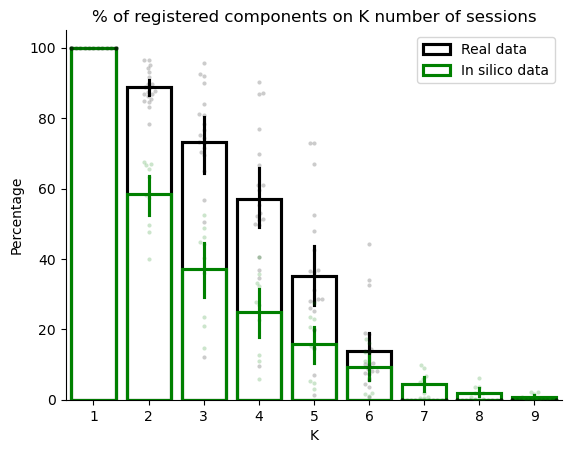

In [13]:
import seaborn as sns

# sns.set_style('whitegrid')
ax = sns.barplot(y='Percentage', x='K', data=data2, fill=False, color='k', label='Real data')
ax = sns.swarmplot(y='Percentage', x='K', data=data2, color='k', s=3, alpha=0.2)

ax = sns.barplot(y='Percentage', x='K', data=data, fill=False, color='green', label='In silico data')
ax = sns.swarmplot(y='Percentage', x='K', data=data, color='green', s=3, alpha=0.2)

plt.title('% of registered components on K number of sessions')
plt.legend()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

In [7]:
session_file = pd.read_csv('data/log/SESSION_FILE_event_associated_cells_definition_2024-10-25_10-51-23.csv')
session_file.head()

,Excluded,Session,Cohort,Date,Mouse,Pair,Criteria,Sex,Final Outcome,Session Outcome,...,USV helper,USV victim,AdaNotes,Comments,Num of Liberation cells,% of Liberation cells,Liberation Associated Cells Metadata Path,Num of Random cells,% of Random cells,Random Associated Cells Metadata Path
0,False,HBTD1,Jan_2024,15.01.2024,8000,8000-7999,SSCW,M,H,NH,...,NaN,NaN,NaN,NaN,NaN,NaN,processed-data/METADATA_Liberation_event_assoc...,NaN,NaN,processed-data/METADATA_Random_event_associate...
1,False,HBTD3,Jan_2024,17.01.2024,8000,8000-7999,SSCW,M,H,H,...,NaN,NaN,NaN,NaN,5.0,13.513514,processed-data/METADATA_Liberation_event_assoc...,5.0,13.513514,processed-data/METADATA_Random_event_associate...
2,False,HBTD4,Jan_2024,18.01.2024,8000,8000-7999,SSCW,M,H,H,...,NaN,NaN,NaN,NaN,3.0,11.538462,processed-data/METADATA_Liberation_event_assoc...,3.0,11.538462,processed-data/METADATA_Random_event_associate...
3,False,HBTD5,Jan_2024,19.01.2024,8000,8000-7999,SSCW,M,H,H,...,NaN,NaN,NaN,NaN,4.0,16.666667,processed-data/METADATA_Liberation_event_assoc...,4.0,16.666667,processed-data/METADATA_Random_event_associate...
4,False,HBTD6,Jan_2024,20.01.2024,8000,8000-7999,SSCW,M,H,H,...,NaN,NaN,NaN,NaN,3.0,13.636364,processed-data/METADATA_Liberation_event_assoc...,3.0,13.636364,processed-data/METADATA_Random_event_associate...
